In [1]:
import os
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns
import numpy as np
from scipy.stats import multinomial
from src.model import Model

# Set the style parameters
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Times New Roman"
fontsize = 27

# Set random seed for reproducibility
seed = 1
np.random.seed(seed)
torch.manual_seed(seed)

# Define the output folder path
output_dir = os.path.join(os.getcwd(), 'toy_kmers_data_example')
os.makedirs(output_dir, exist_ok=True)

In [2]:
# Generate a dataset

# Set the dataset parameters
k = 4 # k value of k-mers
class_num = 5 # Number of classes
sequence_length = 100 # Number of k-mers, (i.e. number of trials of the multinomial distribution)
class_sizes = [25]*class_num # Number of sequences per class
p_intra = 1. # Probability of a sequence belonging to a single class
epsilon = 1e-2 # Small value to avoid zero probabilities in Dirichlet prior
multi_class_seq_num = 5 # Number of sequences belonging to multiple classes

# Certain dimension entries will be prominent for each class so
# each class will have a higher concentration on its own dimensions

# Define the number of k-mers, total sequences and dimension entries for each class
kmers_num = 4**k
sequence_num = sum(class_sizes)
dim_count_per_class = kmers_num // class_num

# Define the parameters of the Multinomial distribution for each class
probs = np.zeros(shape=(class_num, kmers_num))
for class_idx in range(class_num):

    # Set higher concentration for the dimensions corresponding to the current class
    class_dim_indices = np.arange(class_idx*dim_count_per_class, (class_idx+1)*dim_count_per_class)
    # Set them to 1
    probs[class_idx, class_dim_indices] = 1
    # Add small epsilon to all dimensions to avoid zero probabilities
    probs[class_idx, :] += epsilon

    # Last class takes the rest
    if class_idx == class_num - 1:
        probs[class_idx, (class_idx+1)*dim_count_per_class:] = 1

# Normalize to get valid probability distributions
probs = probs / probs.sum(axis=1, keepdims=True)


# Now sample the k-mer counts from the multinomial distribution for each cluster
# The first cluster_sizes[0] points come from cluster 0, next cluster_sizes[1] points come from cluster 1, and so on.
kmer_counts = np.zeros(shape=(sequence_num, kmers_num), dtype=float)
# Define the starting index entry of the first class
start_idx = 0
for class_idx in range(class_num):
    # Define the last entry of the class
    end_idx = start_idx + class_sizes[class_idx]
    # Sample k-mer counts for the current class (sequence_length correspond to the number of kmers, i.e. the number of trials)
    kmer_counts[start_idx:end_idx, :] = multinomial.rvs(sequence_length, probs[class_idx, :], size=class_sizes[class_idx] )
    # Reset the starting index
    start_idx = end_idx

# Now we will generate the positive pairs in order to align with the model's input requirements
# Construct positive pairs by taking two samples from the same cluster
pos_pair_indices = []
for class_idx in range(class_num):
    start = sum(class_sizes[:class_idx])
    end = start + class_sizes[class_idx]
    for i in range(start, end):
        for j in range(i + 1, end):
            if np.random.rand() <= p_intra:  # Only add the pair with probability p_intra
                pos_pair_indices.append([i, j])


# Finally, we will construct the k-mers belonging to multiple classes.
# For this purpose, we will generate 'multi_class_seq_num' number of kmers sequences

# Select the class indices for these k-mer sequences
multi_class_seq_class_indices = np.random.choice(class_num, size=3, replace=False)
# Sample their k-mer counts by summing the counts from the selected classes
multi_class_seq_kmer_counts = np.zeros(shape=(multi_class_seq_num, kmers_num), dtype=float)
for class_idx in multi_class_seq_class_indices:
    # Sample the k-mer counts
    multi_class_seq_kmer_counts += multinomial.rvs(sequence_length, probs[class_idx, :], size=multi_class_seq_num )
    # Add it to the kmer_counts
kmer_counts = np.vstack([kmer_counts, multi_class_seq_kmer_counts])


# Construct the positive pairs for multi-class kmers sequences
for c in multi_class_seq_class_indices:
    start = sum(class_sizes[:c])
    end = start + class_sizes[c]
    for i in range(start, end):
        for j in range(multi_class_seq_num):
            if np.random.rand() <= p_intra:
                pos_pair_indices.append([i, len(kmer_counts)-1-j])


# By using the positive pair indices, construct the positive k-mer frequency pairs
pos_pair_indices = np.array(pos_pair_indices)
normalized_kmers = kmer_counts / np.sum(kmer_counts, axis=1, keepdims=True)
pos_pairs = list(zip(normalized_kmers[pos_pair_indices[:, 0]], normalized_kmers[pos_pair_indices[:, 1]]))

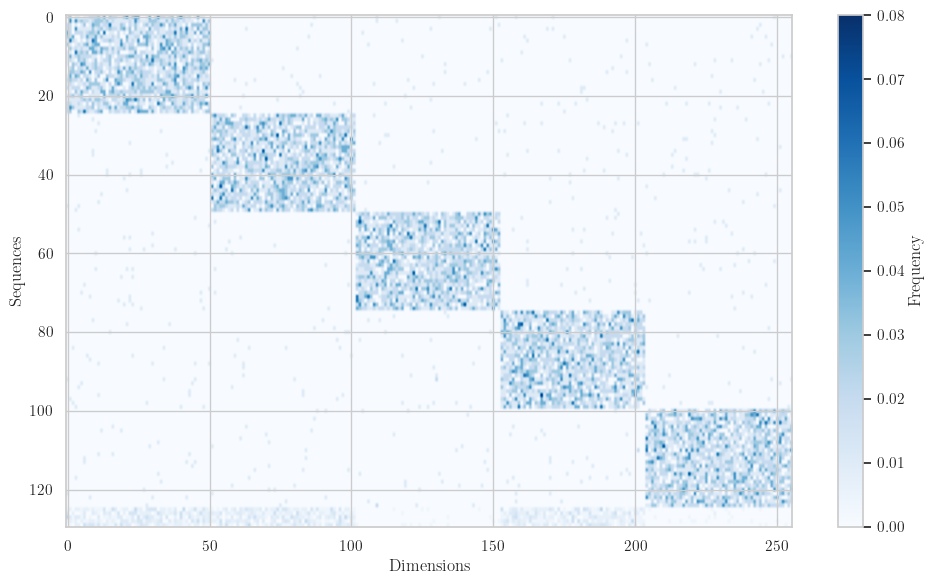

In [3]:
# Plot the sampled normalized k-mer counts
plt.figure(figsize=(10, 6))
# plt.title('K-mer Frequency Distribution Across Sequences')
plt.imshow(normalized_kmers, aspect='auto', cmap='Blues')
plt.colorbar(label='Frequency')
plt.xlabel('Dimensions')
plt.ylabel('Sequences')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'kmers_frequency_distribution.png'))

# Write the normalized positive pair k-mer count pairs to a CSV file
data_file_path = os.path.join(output_dir, 'toy_normalized_kmer_data.csv')
with open(data_file_path, 'w') as f:
    for left, right in pos_pairs:
        left = ' '.join(map(str, left))
        right = ' '.join(map(str, right))
        f.write(f"{left},{right}\n")

In [4]:
# Train the model

# Define model parameters
out_dim = 2
neg_sample_per_pos = 4
lr = 0.01
batch_size = 200
device = "mps"

# Define file paths
model_file_path = os.path.join(output_dir, 'kmer_toy_example.model')

# Define the command to train the model
cmd=f"python {os.path.join(os.getcwd(), '..', 'src','model.py')}"
cmd+=f" --input {data_file_path} --input_type kmer --k {k} --out_dim {out_dim} --neg_sample_per_pos {neg_sample_per_pos} --max_seq_num 0"
cmd+=f" --lr {lr} --batch_size {batch_size} --save_every 0 --distributed 0 --device {device} --loss_name mahalanobis --seed {seed}"
# Run the command for mean_only and var_only states sequentially
os.system(f"{cmd} --epoch 50 --strategy mean_only --output {model_file_path}")
os.system(f"{cmd} --epoch 25 --strategy var_only --checkpoint {model_file_path} --output {model_file_path}")


+ Information
	- k value: 4
	- Loss name: mahalanobis
	- Epoch number: 50
	- Batch size: 200
	- Learning rate: 0.01
	- Output dimension: 2
	- Negative sample per positive pair: 4
	- Maximum number of sequence pairs to use: 0
	- Learning starting strategy: mean_only
	- No distributed training
	- Device: mps
	- Number of data loading workers: 2
	- Seed value: 1
	- Output model name: kmer_toy_example.model
+ Reading the data file.
	- File path: /Users/abdulkadircelikkanat/Downloads/silicem/analysis/toy_kmers_data_example/toy_normalized_kmer_data.csv
	- Completed in 0.17 seconds.
	- The input file contains: 1875 sequence pairs.
	- For training, 0 sequence pairs will be used.
+ Constructing the indices for positive and negative sample pairs
	- Completed in 0.02 seconds.
	- Training dataset contains 1875 positive pairs.
	- Training dataset contains 7500 negative pairs.
+ Training started.
	- Epoch: 1/50 - Loss: 9.040270866231715 (4.02 secs)
	- Epoch: 2/50 - Loss: 9.17451769240359 (1.99 secs)

0

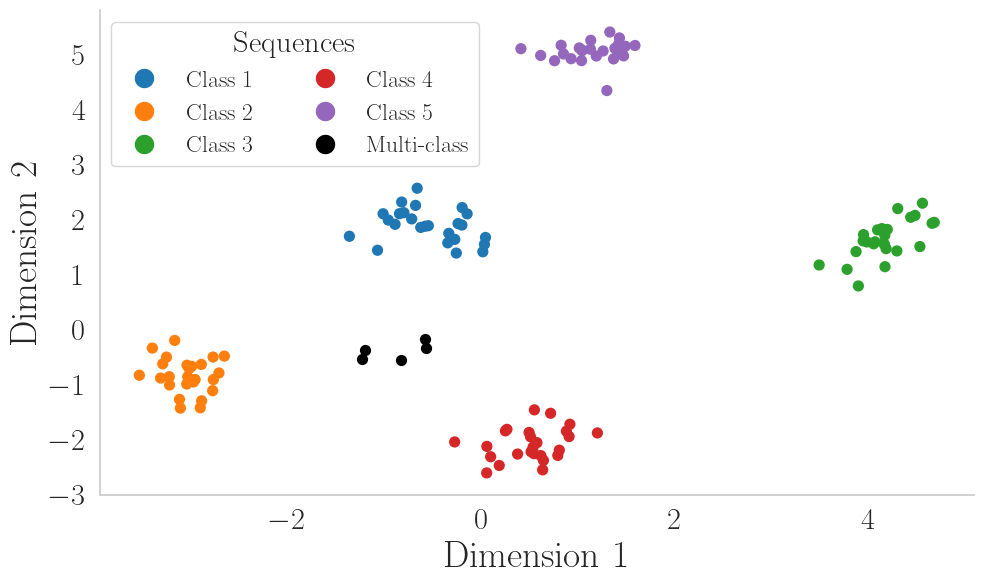

In [5]:
# Plot the embedding space

# Load the model and get the mean and covariance terms
kwargs, model_state_dict = torch.load(model_file_path, map_location=torch.device("cpu"))
model = Model(**kwargs)
model.load_state_dict(model_state_dict)
means, covs = model.seq2emb(normalized_kmers, input_type='Kmer')

# Plot the figure
class_indices = np.array([i // (sequence_num // class_num) for i in range(sequence_num)])
colors = mpl.colormaps['tab10']  # Get a colormap with K distinct colors
seq_colors = colors(class_indices)
plt.figure(figsize=(10, 6))
# plt.title('2D Embeddings of k-mer sequences')
plt.scatter(means[:sequence_num, 0], means[:sequence_num, 1], c=seq_colors, s=50, alpha=1.)
for i in range(multi_class_seq_num):
    plt.scatter(means[sequence_num + i, 0], means[sequence_num + i, 1], c='black', marker='o', s=50, label=f'New Seq {i+1}')

plt.xlabel('Dimension 1', fontsize=fontsize)
plt.ylabel('Dimension 2', fontsize=fontsize)
plt.grid(False)
# Add legend for classes
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors(i), markersize=15, label=f'Class {i+1}') for i in range(class_num)]
handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=15, label='Multi-class'))
plt.legend(handles=handles, title='Sequences', loc='upper left', fontsize=fontsize-10, title_fontsize=fontsize-5, ncols=2)
# Remove the box around the plot
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# Adjust the axis font sizes
plt.xticks(fontsize=fontsize-5)
plt.yticks(fontsize=fontsize-5)
# Remove the blank space around the plot
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'embedding_space.png'))
# plt.show()


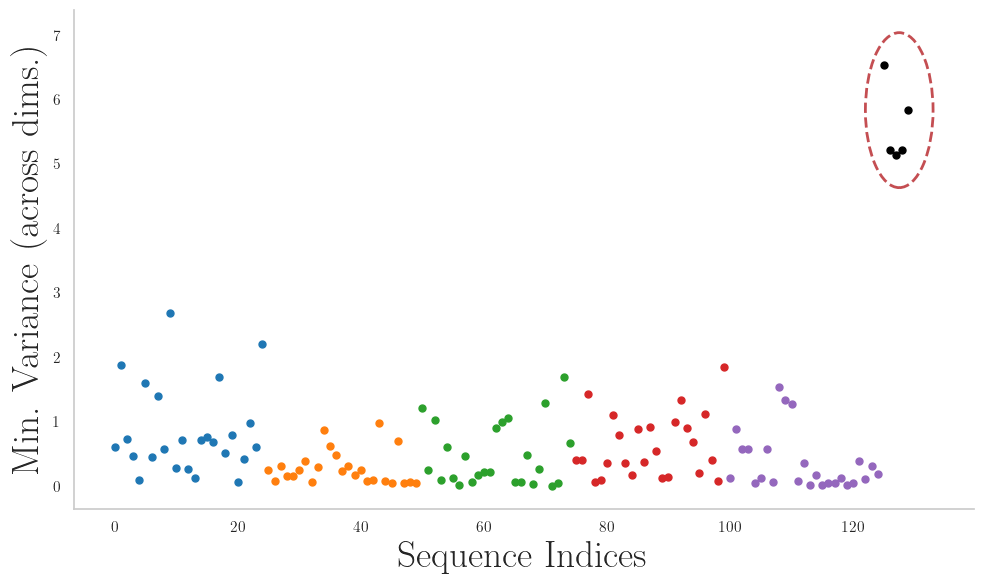

In [6]:
# Plot the distribution of the sequences

# Get the maximum element of covariance values across dimensions
selected_cov_values = covs[:, :].max(axis=-1)
# Get a colormap with K distinct colors
colors = mpl.colormaps['tab10']

plt.figure(figsize=(10, 6))
# plt.title('Covariance of K-mer Sequences')
for i in range(multi_class_seq_num):
    # Get the beginning and last indices of the class
    class_start_idx, class_end_idx = sum(class_sizes[:i]), sum(class_sizes[:i]) + class_sizes[i]
    # Plot the single class variance terms
    plt.plot(range(class_start_idx, class_end_idx), selected_cov_values[class_start_idx:class_end_idx], '.', markersize=10, color=colors(i))
# Plot the multi-class variance terms
plt.plot(range(sequence_num, sequence_num+multi_class_seq_num), selected_cov_values[sequence_num:], '.',  markersize=10, color='black')
# For the multi-class sequences, draw an ellipse
center_x = sequence_num + multi_class_seq_num/2
center_y = (selected_cov_values[sequence_num:].max() + selected_cov_values[sequence_num:].min()) / 2
# Width is equal to the number of multi class sequences + a padding value
width = multi_class_seq_num + 6
# Height is the distance between the max and min of the multi-class variance terms + a padding value
height = selected_cov_values[sequence_num:].max() - selected_cov_values[sequence_num:].min() + 1.
ellipse = Ellipse(
    (center_x,center_y), width=width, height=height, angle=0,
    edgecolor='r', facecolor='none', linestyle='--', linewidth=2, label='Multi-class Sequences'
)
plt.gca().add_patch(ellipse)

# Remove the top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Sequence Indices', fontsize=fontsize)
plt.ylabel('Min. Variance (across dims.)', fontsize=fontsize)
# Remove the grid
plt.grid(False)
plt.tight_layout()
# plt.show()
plt.savefig(os.path.join(output_dir, 'variance_distribution.png'))